# A · Exchange patterns

[Figure 3 index](../README.md#figure-3) · [Complete
assembly](figure3_assembly.ipynb#complete-figure-3).

Figure 3A asks what each pair exchanges, before introducing Social Rank.
This page shows the three heatmaps separately. [Figure
3B](06_figure3b_tokens_by_rank.ipynb) then adds rank differences, and
[Figure 3C](07_figure3c_cooperation_gap.ipynb) shows the Cooperation GAP.
The [assembly page](figure3_assembly.ipynb) combines all nine panels with
the row headers.

# From directed decisions to exchange cells

Each unordered pair has two transfers, `tokens_sent` and
`tokens_received`, both on the original 0–10 allocation scale. The
larger transfer is stored as `high` and the smaller as `low`; folding
the grid this way puts both orientations of the pair in the same cell.
These axes describe the larger and smaller transfer, regardless of which
child has higher Social Rank.

The heatmaps use three groups: non-friends, mutual friends, and all
asymmetric friendships. Both nomination directions enter the asymmetric
heatmap. Each pair appears in two directed rows, so counting both rows
doubles every cell count equally and leaves the within-group percentages
unchanged.

In [ ]:
here::i_am("notebooks/main/05_figure3a_exchange_patterns.qmd")
library(tidyverse)
library(here)
source(here("code", "00_style.R"))

The data are reused if `analysis_dyads` and `analysis_students` are
already in R. Otherwise, this step loads their CSV files from
`data/generated/main/`, or builds them from the raw inputs on first use.

In [ ]:
source(here("code", "00_load_main_data.R"), local = TRUE)
dyads <- analysis_dyads

In [ ]:
main_data_status

dataset,rows,source
analysis_dyads,17804,Saved CSV files
analysis_students,859,Saved CSV files


The next chunk builds two auxiliary tables for panel A from
`analysis_dyads`. `heatmap_cells` contains the exchange-cell counts and
percentages; `heatmap_regions` sums the percentages within each
highlighted region. The heatmap function uses these tables to draw the
panels.

In [ ]:
# Panel A. Every pair exchanges two numbers: what i sends to j and what j
# sends to i. The order does not matter for the heatmap (5 and 2 is the same
# pair as 2 and 5), so we keep the larger number on the x axis and the
# smaller on the y axis. That is why the heatmap is a triangle.
#
# One-sided friendships appear twice in the data (as "Sender declares" from
# one side and "Receiver declares" from the other), so for the heatmap we put
# both together in one "Asymmetric" group. Percentages are computed within
# each group.

heatmap_cells <- dyads %>%
  mutate(group = case_when(friendship == "Non-friends" ~ "Non-friends",
                           friendship == "Mutual"      ~ "Mutual friends",
                           TRUE                        ~ "Asymmetric"),
         high = pmax(tokens_sent, tokens_received),
         low  = pmin(tokens_sent, tokens_received)) %>%
  count(group, high, low) %>%
  group_by(group) %>%
  mutate(percent = 100 * n / sum(n)) %>%
  ungroup() %>%
  # add the combinations that never happened, with 0%
  complete(group, high = 0:10, low = 0:10, fill = list(n = 0, percent = 0)) %>%
  filter(low <= high)

# Three regions highlighted in the paper
heatmap_regions <- heatmap_cells %>%
  group_by(group) %>%
  summarise(
    low_cooperation  = sum(percent[high <= 1]),                 # both sent 0 or 1 (magenta)
    asymmetric       = sum(percent[high == 10 & low <= 5]),     # one sent 10, the other 5 or less (blue)
    full_cooperation = sum(percent[high == 10 & low == 10])     # both sent 10 (black)
  )

heatmap_regions

In [ ]:
heatmap_regions

group,low_cooperation,asymmetric,full_cooperation
Asymmetric,5.076923,28.53846,14.615385
Mutual friends,2.639752,22.82609,28.416149
Non-friends,11.971831,22.99511,6.438632


The highlighted regions have explicit definitions: both transfers at
most one token; one transfer of ten and the other at most five; and both
transfers equal to ten. The unequal-exchange region is narrower than a
rule based on any difference of at least five tokens.

# Inspect the underlying percentages

The table below lists the five most frequent exchange cells within each
relationship group. `high` and `low` give the two heatmap coordinates,
and `percent` gives the value drawn in that cell.

In [ ]:
heatmap_cells %>%
  group_by(group) %>%
  slice_max(percent, n = 5, with_ties = FALSE) %>%
  ungroup()

group,high,low,n,percent
Asymmetric,10,10,380,14.615385
Asymmetric,10,4,144,5.538462
Asymmetric,10,2,142,5.461538
Asymmetric,10,0,138,5.307692
Asymmetric,10,6,118,4.538462
Mutual friends,10,10,366,28.416149
Mutual friends,10,2,76,5.900621
Mutual friends,10,6,66,5.124224
Mutual friends,10,3,56,4.347826
Mutual friends,10,8,56,4.347826


# Example: draw non-friends directly

Draw the non-friend heatmap from its cell percentages and region totals
using explicit `ggplot()` layers. The plot uses the same cells,
annotations, and scales as the function below.

In [ ]:
# Draw the non-friend heatmap directly from the exchange-cell table.
non_friend_cells <- heatmap_cells %>% filter(group == "Non-friends")
non_friend_regions <- heatmap_regions %>% filter(group == "Non-friends")

heatmap_non_friends <- ggplot(non_friend_cells, aes(x = high, y = low, fill = percent)) +
  geom_tile(color = "white") +
  geom_text(aes(label = round(percent, 1)), size = 2) +
  # magenta: low or no cooperation
  annotate("rect", xmin = -0.5, xmax = 1.5, ymin = -0.5, ymax = 1.5,
           color = "#F000D0", fill = NA, linewidth = 0.8) +
  annotate("label", x = 0.5, y = 2, label = round(non_friend_regions$low_cooperation, 1),
           color = "#F000D0", size = 2.3, fontface = "bold") +
  # blue: highly asymmetric
  annotate("rect", xmin = 9.5, xmax = 10.5, ymin = -0.5, ymax = 5.5,
           color = "#173BFF", fill = NA, linewidth = 0.8) +
  annotate("label", x = 11, y = 5.5, label = round(non_friend_regions$asymmetric, 1),
           color = "#173BFF", size = 2.3, fontface = "bold") +
  # black: full mutual cooperation
  annotate("rect", xmin = 9.5, xmax = 10.5, ymin = 9.5, ymax = 10.5,
           color = "black", fill = NA, linewidth = 0.9) +
  scale_fill_gradientn(colours = c("#FFF4D6", "#F7E08A", "#E7B56A", "#D9874C", "#C95A3A", "#A51C1C"),
                       values = scales::rescale(c(0, 2, 5, 10, 15, 20)),
                       limits = c(0, 20), oob = scales::squish, name = "%") +
  scale_x_continuous(breaks = 0:10, expand = c(0, 0)) +
  scale_y_continuous(breaks = 0:10, expand = c(0, 0)) +
  coord_fixed(clip = "off") +
  labs(x = "Tokens i to j", y = "Tokens j to i", title = "Non-friends") +
  theme_paper(base_size = 9) +
  theme(panel.border = element_blank(), legend.position = "right")

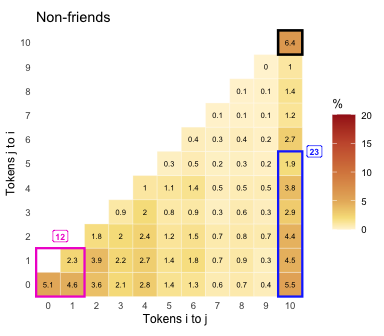

In [ ]:
heatmap_non_friends

# The reusable heatmap function

The function below packages the same layers. Its argument selects a
relationship group from the tables inspected above.

In [ ]:
plot_heatmap <- function(this_group) {
  cells   <- heatmap_cells   %>% filter(group == this_group)
  regions <- heatmap_regions %>% filter(group == this_group)

  ggplot(cells, aes(x = high, y = low, fill = percent)) +
    geom_tile(color = "white") +
    geom_text(aes(label = round(percent, 1)), size = 2) +
    # magenta: low or no cooperation
    annotate("rect", xmin = -0.5, xmax = 1.5, ymin = -0.5, ymax = 1.5,
             color = "#F000D0", fill = NA, linewidth = 0.8) +
    annotate("label", x = 0.5, y = 2, label = round(regions$low_cooperation, 1),
             color = "#F000D0", size = 2.3, fontface = "bold") +
    # blue: highly asymmetric
    annotate("rect", xmin = 9.5, xmax = 10.5, ymin = -0.5, ymax = 5.5,
             color = "#173BFF", fill = NA, linewidth = 0.8) +
    annotate("label", x = 11, y = 5.5, label = round(regions$asymmetric, 1),
             color = "#173BFF", size = 2.3, fontface = "bold") +
    # black: full mutual cooperation
    annotate("rect", xmin = 9.5, xmax = 10.5, ymin = 9.5, ymax = 10.5,
             color = "black", fill = NA, linewidth = 0.9) +
    scale_fill_gradientn(colours = c("#FFF4D6", "#F7E08A", "#E7B56A", "#D9874C", "#C95A3A", "#A51C1C"),
                         values = scales::rescale(c(0, 2, 5, 10, 15, 20)),
                         limits = c(0, 20), oob = scales::squish, name = "%") +
    scale_x_continuous(breaks = 0:10, expand = c(0, 0)) +
    scale_y_continuous(breaks = 0:10, expand = c(0, 0)) +
    coord_fixed(clip = "off") +
    labs(x = "Tokens i to j", y = "Tokens j to i", title = this_group) +
    theme_paper(base_size = 9) +
    theme(panel.border = element_blank(), legend.position = "right")
}

# Mutual friends

In [ ]:
heatmap_mutual <- plot_heatmap("Mutual friends")

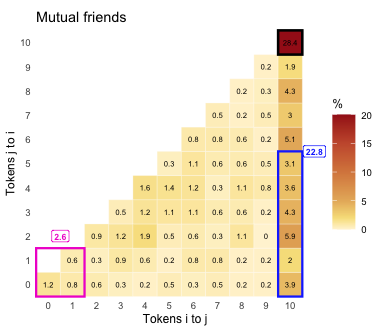

In [ ]:
heatmap_mutual

# Asymmetric friendships

In [ ]:
heatmap_asymmetric <- plot_heatmap("Asymmetric")

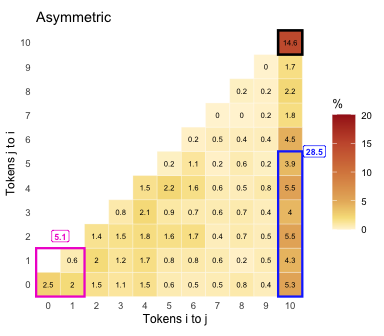

In [ ]:
heatmap_asymmetric

The command-line replication saves the full cell table as
`output/tables/figure3_heatmap_cells.csv`. The [Figure 3 summary
dictionary](../../data/figure3_codebook.md#figure-3-summary-tables) defines these
fields and the summaries used in the next two pages.

# Session information

In [ ]:
sessionInfo()
## R version 4.3.2 (2023-10-31)
## Platform: aarch64-apple-darwin20 (64-bit)
## Running under: macOS 26.7.1
## 
## Matrix products: default
## BLAS:   /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRblas.0.dylib 
## LAPACK: /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRlapack.dylib;  LAPACK version 3.11.0
## 
## locale:
## [1] C.UTF-8/C.UTF-8/C.UTF-8/C/C.UTF-8/C.UTF-8
## 
## time zone: America/Santiago
## tzcode source: internal
## 
## attached base packages:
## [1] stats     graphics  grDevices utils     datasets  methods   base     
## 
## other attached packages:
##  [1] lubridate_1.9.4 forcats_1.0.0   stringr_1.5.1   dplyr_1.1.4    
##  [5] purrr_1.0.4     readr_2.1.5     tidyr_1.3.1     tibble_3.2.1   
##  [9] ggplot2_3.5.2   tidyverse_2.0.0 here_1.0.1     
## 
## loaded via a namespace (and not attached):
##  [1] bit_4.6.0         gtable_0.3.6      jsonlite_2.0.0    crayon_1.5.3     
##  [5] compiler_4.3.2    tidyselect_1.2.1  parallel_4.3.2    scales_1.3.0     
##  [9] yaml_2.3.10       fastmap_1.2.0     R6_2.6.1          labeling_0.4.3   
## [13] generics_0.1.3    knitr_1.50        munsell_0.5.1     rprojroot_2.0.4  
## [17] pillar_1.10.2     tzdb_0.5.0        rlang_1.1.6       stringi_1.8.7    
## [21] xfun_0.52         bit64_4.6.0-1     timechange_0.3.0  cli_3.6.4        
## [25] withr_3.0.2       magrittr_2.0.3    digest_0.6.37     grid_4.3.2       
## [29] vroom_1.6.5       hms_1.1.3         lifecycle_1.0.4   vctrs_0.6.5      
## [33] evaluate_1.0.3    glue_1.8.0        farver_2.1.2      colorspace_2.1-1 
## [37] rmarkdown_2.29    tools_4.3.2       pkgconfig_2.0.3   htmltools_0.5.8.1

[Continue to Figure 3B: tokens by rank](06_figure3b_tokens_by_rank.ipynb).